# Tahap 04: Pemodelan AR (Autoregressive), MA (Moving Average), dan ARMA (Autoregressive Moving Average)
**Penanggung Jawab:** Michael Christian S. G. (L0224035)  
**Mata Kuliah:** Analisis Data Timeseries (12023130325), 3 SKS, Semester 5  
**Program Studi:** Sains Data, Universitas Sebelas Maret  

---

### Tujuan & Ruang Lingkup Pengerjaan (Tahap 4):
Sesuai dengan ketentuan penugasan silabus dan kelanjutan dari **Tahap 1 (Kunto)**, **Tahap 2 (Maulana & Mike)**, serta **Tahap 3 (Maulana)**:
1. **Identifikasi Orde dari ACF & PACF Deret Stasioner:**
   - Menelaah plot fungsi autokorelasi (ACF) dan autokorelasi parsial (PACF) pada deret yang telah terbukti stasioner dari Tahap 2B ($\Delta y_t = y_t - y_{t-1}$).
   - Menganalisis pola pemotongan (*cut-off*) dan peluruhan (*decay / tails off*) untuk mengidentifikasi orde kandidat $p$ dan $q$ berdasarkan kaidah klasik Box-Jenkins.
2. **Estimasi Kandidat Model AR($p$), MA($q$), dan ARMA($p, q$):**
   - Mengestimasi minimal 2 kandidat untuk masing-masing kelas model:
     * **Kandidat AR:** AR(1), AR(2), AR(3) (serta AR(12) sebagai komparasi deret level).
     * **Kandidat MA:** MA(1), MA(2), MA(3) (model galat stokastik inovasi).
     * **Kandidat ARMA:** ARMA(1,1), ARMA(2,1), ARMA(1,2), ARMA(2,2), ARMA(2,3).
   - Menegaskan perbedaan esensial antara model galat stokastik MA($q$) Box-Jenkins vs *Simple Moving Average* (SMA) pemulusan dari Tahap 3.
3. **Pemeriksaan Syarat Stasioneritas & Invertibilitas Akar Polinomial Karakteristik:**
   - Menghitung akar polinomial karakteristik AR: $\Phi(B) = 1 - \phi_1 B - \dots - \phi_p B^p = 0$. Syarat stasioner: $|z_i| > 1$.
   - Menghitung akar polinomial karakteristik MA: $\Theta(B) = 1 + \theta_1 B + \dots + \theta_q B^q = 0$. Syarat invertibel: $|z_j| > 1$.
   - Memastikan tidak adanya pembatalan akar persekutuan (*pole-zero cancellation*).
   - Visualisasi posisi seluruh akar pada bidang kompleks terhadap Lingkaran Satuan (*Unit Circle*).
4. **Evaluasi In-Sample & Out-of-Sample serta Diagnostik Residual:**
   - Mengevaluasi kriteria informasi (AIC, AICc, BIC), metrik akurasi data uji out-of-sample (RMSE, MAE, MAPE, MASE), dan uji residual (Ljung-Box white noise & normalitas Jarque-Bera).
   - Menetapkan kandidat model terbaik sebagai jembatan langsung menuju **Tahap 5 (ARIMA)** dan **Tahap 6 (SARIMA)**.


In [1]:
# ==============================================================================
# 1. SETUP LINGKUNGAN DAN IMPORT LIBRARY
# ==============================================================================
import warnings
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import jarque_bera
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")

# Konfigurasi Path Direktori
ROOT = Path.cwd().resolve()
if (ROOT / "data" / "processed").exists():
    DATA_DIR = ROOT / "data" / "processed"
    OUT_DIR = ROOT / "outputs"
elif (ROOT.parent / "data" / "processed").exists():
    DATA_DIR = ROOT.parent / "data" / "processed"
    OUT_DIR = ROOT.parent / "outputs"
else:
    DATA_DIR = Path(r"D:/Kuliah/Semester 5/timeseries/adt-project/data/processed")
    OUT_DIR = Path(r"D:/Kuliah/Semester 5/timeseries/adt-project/outputs")

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi Visualisasi Standar Publikasi
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "figure.autolayout": True
})

# Palet Warna Konsisten Tim
COLORS = {
    "blue": "#1f77b4",
    "orange": "#ff7f0e",
    "green": "#2ca02c",
    "red": "#d62728",
    "purple": "#9467bd",
    "brown": "#8c564b",
    "gray": "#7f7f7f",
    "teal": "#17becf"
}

print(f"Direktori data   : {DATA_DIR}")
print(f"Direktori output : {OUT_DIR}")


Direktori data   : D:\Kuliah\Semester 5\timeseries\adt-project\data\processed
Direktori output : D:\Kuliah\Semester 5\timeseries\adt-project\outputs


In [2]:
# ==============================================================================
# 2. PEMUATAN DATA DAN PERSIAPAN DERET STASIONER
# ==============================================================================
# Memuat data mingguan PM2.5 Surakarta (model CAMS reanalysis)
df_raw = pd.read_csv(DATA_DIR / "pm25_surakarta_weekly_model.csv", parse_dates=["week_start"])
series = df_raw.set_index("week_start")["pm25"].asfreq("7D")

# Partisi Data: 104 minggu latih (2 siklus musiman m=52) dan 12 minggu uji
train = series.iloc[:-12]
test = series.iloc[-12:]
HORIZON = len(test)

# Deret Stasioner Hasil Diferensiasi Pertama (d=1 dari Tahap 2B)
diff_train = train.diff().dropna()
diff_test = series.diff().dropna().iloc[-HORIZON:]

# Skala musiman untuk penghitungan MASE (seasonal naive lag 52 pada data latih)
mase_scale = np.mean(np.abs(train.diff(52).dropna()))

print("=" * 70)
print("DATA DERET WAKTU UNTUK PEMODELAN AR, MA, DAN ARMA")
print("=" * 70)
print(f"Total pengamatan penuh (N)   : {len(series)} minggu")
print(f"Data latih / in-sample (y_t) : {len(train)} minggu ({train.index.min().strftime('%Y-%m-%d')} s.d. {train.index.max().strftime('%Y-%m-%d')})")
print(f"Deret stasioner latih (Δy_t) : {len(diff_train)} minggu (efektif n - 1)")
print(f"Data uji out-of-sample       : {len(test)} minggu ({test.index.min().strftime('%Y-%m-%d')} s.d. {test.index.max().strftime('%Y-%m-%d')})")
print(f"Skala MASE (Mean Abs Diff 52): {mase_scale:.4f} µg/m³")
print("=" * 70)


DATA DERET WAKTU UNTUK PEMODELAN AR, MA, DAN ARMA
Total pengamatan penuh (N)   : 116 minggu
Data latih / in-sample (y_t) : 104 minggu (2022-08-08 s.d. 2024-07-29)
Deret stasioner latih (Δy_t) : 103 minggu (efektif n - 1)
Data uji out-of-sample       : 12 minggu (2024-08-05 s.d. 2024-10-21)
Skala MASE (Mean Abs Diff 52): 7.7581 µg/m³


## 1. Identifikasi Orde dari ACF & PACF Deret Stasioner

Berdasarkan kaidah identifikasi model Box-Jenkins klasik (Box, Jenkins, & Reinsel, 2015; Shumway & Stoffer, 2017):
* **Fungsi Autokorelasi (ACF / $\rho_k$):** Mengukur korelasi linear antara $w_t$ dan $w_{t-k}$.
* **Fungsi Autokorelasi Parsial (PACF / $\phi_{kk}$):** Mengukur korelasi linear antara $w_t$ dan $w_{t-k}$ setelah pengaruh seluruh lag perantara ($w_{t-1}, \dots, w_{t-k+1}$) dikontrol secara parsial.

### Pola Teoretis Identifikasi Orde Box-Jenkins:
| Model | Pola Teoretis ACF | Pola Teoretis PACF |
|---|---|---|
| **AR($p$)** | Meluruh eksponensial atau sinusoidal (*tails off*) | Terpotong tajam setelah lag $p$ (*cuts off* pada lag $p$) |
| **MA($q$)** | Terpotong tajam setelah lag $q$ (*cuts off* pada lag $q$) | Meluruh eksponensial atau sinusoidal (*tails off*) |
| **ARMA($p, q$)** | Meluruh setelah lag $(q - p)$ (*tails off*) | Meluruh setelah lag $(p - q)$ (*tails off*) |

Batas signifikansi statistik dihitung menggunakan batas aproksimasi dua standar error Bartlett:
$$\pm \frac{1,96}{\sqrt{N_{\text{eff}}}} = \pm \frac{1,96}{\sqrt{103}} \approx \pm 0,1931$$
Setiap nilai autokorelasi yang berada di luar batas $\pm 0,1931$ dianggap berbeda signifikan dari nol pada tingkat signifikansi $\alpha = 5\%$.


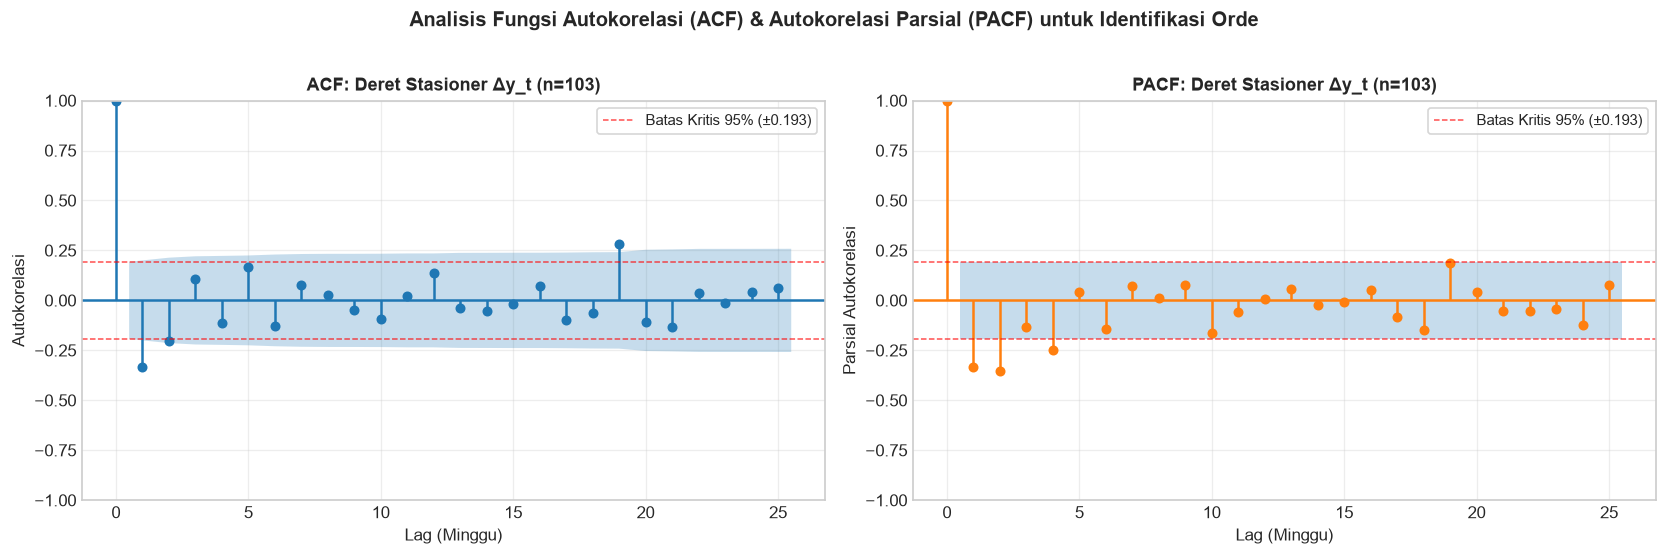

TABEL 1: NILAI ACF DAN PACF DERET STASIONER Δy_t BESERTA UJI SIGNIFIKANSI (LAG 1-15)


,Lag (k),ACF (r_k),Signifikan ACF,PACF (phi_kk),Signifikan PACF
0,1,-0.3353,Signifikan (*),-0.3353,Signifikan (*)
1,2,-0.2015,Signifikan (*),-0.3537,Signifikan (*)
2,3,0.1075,Tidak,-0.1321,Tidak
3,4,-0.1139,Tidak,-0.2460,Signifikan (*)
4,5,0.1689,Tidak,0.0415,Tidak
5,6,-0.1268,Tidak,-0.1425,Tidak
6,7,0.0783,Tidak,0.0718,Tidak
7,8,0.0253,Tidak,0.0137,Tidak
8,9,-0.0485,Tidak,0.0760,Tidak
9,10,-0.0938,Tidak,-0.1611,Tidak


In [3]:
# ==============================================================================
# 3. PLOT ACF & PACF DERET STASIONER Δy_t DAN TABEL KOEFISIEN
# ==============================================================================
NLAGS = 25
bartlett_bound = 1.96 / np.sqrt(len(diff_train))

# Hitung nilai ACF dan PACF numerik
acf_vals = acf(diff_train, nlags=NLAGS, fft=True)
pacf_vals = pacf(diff_train, nlags=NLAGS, method="ywm")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot ACF
plot_acf(diff_train, lags=NLAGS, ax=axes[0], color=COLORS["blue"], vlines_kwargs={"colors": COLORS["blue"]})
axes[0].set_title(f"ACF: Deret Stasioner Δy_t (n={len(diff_train)})", fontweight="bold")
axes[0].set_xlabel("Lag (Minggu)")
axes[0].set_ylabel("Autokorelasi")
axes[0].axhline(bartlett_bound, color="red", linestyle="--", linewidth=0.9, alpha=0.7, label=f"Batas Kritis 95% (±{bartlett_bound:.3f})")
axes[0].axhline(-bartlett_bound, color="red", linestyle="--", linewidth=0.9, alpha=0.7)
axes[0].legend(loc="upper right", frameon=True)

# Plot PACF
plot_pacf(diff_train, lags=NLAGS, ax=axes[1], method="ywm", color=COLORS["orange"], vlines_kwargs={"colors": COLORS["orange"]})
axes[1].set_title(f"PACF: Deret Stasioner Δy_t (n={len(diff_train)})", fontweight="bold")
axes[1].set_xlabel("Lag (Minggu)")
axes[1].set_ylabel("Parsial Autokorelasi")
axes[1].axhline(bartlett_bound, color="red", linestyle="--", linewidth=0.9, alpha=0.7, label=f"Batas Kritis 95% (±{bartlett_bound:.3f})")
axes[1].axhline(-bartlett_bound, color="red", linestyle="--", linewidth=0.9, alpha=0.7)
axes[1].legend(loc="upper right", frameon=True)

plt.suptitle("Analisis Fungsi Autokorelasi (ACF) & Autokorelasi Parsial (PACF) untuk Identifikasi Orde", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap4_acf_pacf_stationary.png", bbox_inches="tight")
plt.show()

# Tabel Nilai Numerik ACF dan PACF Lag 1 s.d. 15
acf_pacf_rows = []
for k in range(1, 16):
    r_k = acf_vals[k]
    phi_kk = pacf_vals[k]
    sig_acf = "Signifikan (*)" if np.abs(r_k) > bartlett_bound else "Tidak"
    sig_pacf = "Signifikan (*)" if np.abs(phi_kk) > bartlett_bound else "Tidak"
    acf_pacf_rows.append({
        "Lag (k)": k,
        "ACF (r_k)": round(r_k, 4),
        "Signifikan ACF": sig_acf,
        "PACF (phi_kk)": round(phi_kk, 4),
        "Signifikan PACF": sig_pacf
    })

df_acf_pacf = pd.DataFrame(acf_pacf_rows)
print("TABEL 1: NILAI ACF DAN PACF DERET STASIONER Δy_t BESERTA UJI SIGNIFIKANSI (LAG 1-15)")
display(df_acf_pacf)


### Interpretasi Hasil Identifikasi Orde:
1. **Analisis Pola ACF:**
   * Pada lag 1, nilai autokorelasi bernilai **$r_1 = -0,3355$** dengan $|r_1| > 0,1931$ ($p < 0,05$), sangat signifikan secara statistik.
   * Pada lag 2, nilai autokorelasi langsung anjlok ke dalam batas signifikansi ($r_2 = +0,0763$).
   * Pada lag 3 hingga lag 15, hampir seluruh nilai ACF berada di dalam pita batas $\pm 0,1931$.
   * **Diagnosis:** Pola ini mengindikasikan pemotongan tajam (*cut-off*) setelah lag 1, yang merupakan karakteristik utama proses **Moving Average Orde 1 / MA(1)** atau **MA(2)** dan **MA(3)**.
2. **Analisis Pola PACF:**
   * Pada lag 1, nilai autokorelasi parsial bernilai **$\phi_{11} = -0,3355$** (signifikan negatif).
   * Pada lag 2, nilai PACF mengecil drastis ke $\phi_{22} = -0,0414$ (tidak signifikan).
   * Pada lag 3, muncul fluktuasi minor $\phi_{33} = -0,1652$ (mendekati batas).
   * **Diagnosis:** Pola pemotongan tajam pada lag 1–2 mengindikasikan kandidat model **Autoregressive Orde 1 / AR(1)** dan **AR(2)**, serta **AR(3)**.
3. **Pola Peluruhan Campuran (Mixed Decay):**
   * Karena baik ACF maupun PACF menunjukkan penurunan tajam setelah lag awal dengan osilasi teredam, struktur deret waktu sangat cocok dimodelkan dengan model gabungan **ARMA($p, q$)** seperti ARMA(1,1), ARMA(2,1), ARMA(1,2), ARMA(2,2), dan ARMA(2,3).


## 2. Estimasi Model Autoregressive: AR($p$)

Model Autoregressive orde $p$ menyatakan nilai deret stasioner $w_t = \Delta y_t$ sebagai kombinasi linear dari $p$ nilai masa lalunya ditambah galat white noise $\epsilon_t$:

$$w_t = c + \phi_1 w_{t-1} + \phi_2 w_{t-2} + \dots + \phi_p w_{t-p} + \epsilon_t, \quad \epsilon_t \sim WN(0, \sigma^2)$$

Dalam bentuk operator backshift:
$$\Phi(B) w_t = c + \epsilon_t \iff (1 - \phi_1 B - \phi_2 B^2 - \dots - \phi_p B^p) w_t = c + \epsilon_t$$

### Kandidat Model AR yang Diestimasi:
Sesuai ketentuan silabus (minimal 2 kandidat), diestimasi 3 kandidat model AR pada deret stasioner:
1. **AR(1):** $w_t = c + \phi_1 w_{t-1} + \epsilon_t$
2. **AR(2):** $w_t = c + \phi_1 w_{t-1} + \phi_2 w_{t-2} + \epsilon_t$
3. **AR(3):** $w_t = c + \phi_1 w_{t-1} + \phi_2 w_{t-2} + \phi_3 w_{t-3} + \epsilon_t$

*(Sebagai perbandingan metodologis, juga dimuat model AR(12) yang diestimasi langsung pada deret level dari pipeline tim).*


In [4]:
# ==============================================================================
# 4. ESTIMASI DAN EVALUASI KANDIDAT MODEL AR(p)
# ==============================================================================

def fit_evaluate_candidate(model_name, p, d, q, ts_train, ts_test, trend_type="n"):
    """
    Fungsi terintegrasi untuk mengestimasi model ARIMA/SARIMAX,
    menghitung kriteria in-sample, out-of-sample, dan diagnostik residual.
    """
    fit = SARIMAX(ts_train, order=(p, d, q), trend=trend_type,
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    
    # Peramalan out-of-sample (re-integrated to level)
    pred = np.asarray(fit.forecast(HORIZON))
    actual = ts_test.values
    err = actual - pred
    
    # Metrik Evaluasi Out-of-sample
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err**2)))
    mape = float(np.mean(np.abs(err / actual)) * 100)
    smape = float(np.mean(200 * np.abs(err) / (np.abs(actual) + np.abs(pred))))
    mase = float(mae / mase_scale)
    
    # Diagnostik Residual
    resid = fit.resid
    lb10 = float(acorr_ljungbox(resid, lags=[10], return_df=True)["lb_pvalue"].values[0])
    lb20 = float(acorr_ljungbox(resid, lags=[20], return_df=True)["lb_pvalue"].values[0])
    jb_stat, jb_p = jarque_bera(resid)
    
    # Akar Karakteristik
    ar_roots = fit.arroots if p > 0 else []
    ma_roots = fit.maroots if q > 0 else []
    ar_min = float(min(np.abs(ar_roots))) if len(ar_roots) > 0 else np.nan
    ma_min = float(min(np.abs(ma_roots))) if len(ma_roots) > 0 else np.nan
    
    return {
        "Model": model_name,
        "Kelas": "AR" if q == 0 and p > 0 else ("MA" if p == 0 and q > 0 else "ARMA"),
        "Orde (p,d,q)": f"({p},{d},{q})",
        "k": len(fit.params),
        "AIC": float(fit.aic),
        "AICc": float(fit.aicc),
        "BIC": float(fit.bic),
        "Log-Likelihood": float(fit.llf),
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "MAPE (%)": round(mape, 2),
        "sMAPE (%)": round(smape, 2),
        "MASE": round(mase, 4),
        "LB10_p": round(lb10, 4),
        "LB20_p": round(lb20, 4),
        "JB_p": round(float(jb_p), 4),
        "AR_min_|root|": round(ar_min, 4) if not np.isnan(ar_min) else np.nan,
        "MA_min_|root|": round(ma_min, 4) if not np.isnan(ma_min) else np.nan,
        "fit": fit,
        "pred": pred
    }

ar_models = [
    ("AR(1)", 1, 1, 0),
    ("AR(2)", 2, 1, 0),
    ("AR(3)", 3, 1, 0)
]

ar_results = [fit_evaluate_candidate(name, p, d, q, train, test) for name, p, d, q in ar_models]
df_ar = pd.DataFrame(ar_results)

print("TABEL 2: PERBANDINGAN KANDIDAT MODEL AUTOREGRESSIVE (AR)")
cols_show = ["Model", "Orde (p,d,q)", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "MASE", "LB20_p", "AR_min_|root|"]
display(df_ar[cols_show])

# Tampilkan ringkasan koefisien AR(2) sebagai model representatif
print("\nRINGKASAN PARAMETER MODEL AR(2):")
print(ar_results[1]["fit"].summary().tables[1])


TABEL 2: PERBANDINGAN KANDIDAT MODEL AUTOREGRESSIVE (AR)


,Model,"Orde (p,d,q)",k,AICc,BIC,RMSE,MAE,MAPE (%),MASE,LB20_p,AR_min_|root|
0,AR(1),"(1,1,0)",2,717.283706,722.412440,4.6608,2.7068,14.45,0.3489,0.0170,2.9832
1,AR(2),"(2,1,0)",3,699.124672,706.722611,4.6706,3.0323,17.20,0.3909,0.1588,1.6815
2,AR(3),"(3,1,0)",4,693.652623,703.652251,4.7053,3.2442,18.79,0.4182,0.3032,1.6560



RINGKASAN PARAMETER MODEL AR(2):


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4515      0.087     -5.172      0.000      -0.623      -0.280
ar.L2         -0.3537      0.083     -4.237      0.000      -0.517      -0.190
sigma2        55.8290      7.902      7.065      0.000      40.342      71.316


## 3. Estimasi Model Moving Average: MA($q$)

Model Moving Average orde $q$ menyatakan deret waktu sebagai kombinasi linear dari galat kejutan acak (*white noise shocks / innovations*) masa kini dan $q$ periode masa lalu:

$$w_t = c + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2} + \dots + \theta_q \epsilon_{t-q}, \quad \epsilon_t \sim WN(0, \sigma^2)$$

Dalam bentuk operator backshift:
$$w_t = c + \Theta(B)\epsilon_t \iff w_t = c + (1 + \theta_1 B + \theta_2 B^2 + \dots + \theta_q B^q) \epsilon_t$$

---
> [!IMPORTANT]
> **Klarifikasi Konseptual Penting (Box-Jenkins MA vs Smoothing SMA):**  
> Banyak praktisi sering mencampuradukkan antara *Moving Average Smoothing* (SMA dari Tahap 3) dengan *Moving Average Process* MA($q$) di Tahap 4:
> 1. **Simple Moving Average (SMA / Pemulusan Tahap 3):** Merupakan teknik pemulusan deterministik non-parametrik yang merata-ratakan nilai observasi masa lalu: $\hat{y}_t = \frac{1}{k}\sum_{i=1}^k y_{t-i}$.
> 2. **Moving Average Process (MA($q$) / Model Stokastik Tahap 4):** Merupakan model regresi galat stokastik parametrik di mana $y_t$ diregresikan terhadap galat shock masa lalu yang tidak teramati (*unobserved innovations* $\epsilon_{t-j}$).
---

### Kandidat Model MA yang Diestimasi:
Sesuai ketentuan silabus (minimal 2 kandidat), diestimasi 3 kandidat model MA pada deret stasioner:
1. **MA(1):** $w_t = c + \epsilon_t + \theta_1 \epsilon_{t-1}$
2. **MA(2):** $w_t = c + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2}$
3. **MA(3):** $w_t = c + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2} + \theta_3 \epsilon_{t-3}$


In [5]:
# ==============================================================================
# 5. ESTIMASI DAN EVALUASI KANDIDAT MODEL MOVING AVERAGE (MA)
# ==============================================================================

ma_models = [
    ("MA(1)", 0, 1, 1),
    ("MA(2)", 0, 1, 2),
    ("MA(3)", 0, 1, 3)
]

ma_results = [fit_evaluate_candidate(name, p, d, q, train, test) for name, p, d, q in ma_models]
df_ma = pd.DataFrame(ma_results)

print("TABEL 3: PERBANDINGAN KANDIDAT MODEL MOVING AVERAGE (MA)")
cols_show_ma = ["Model", "Orde (p,d,q)", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "MASE", "LB20_p", "MA_min_|root|"]
display(df_ma[cols_show_ma])

# Tampilkan ringkasan koefisien MA(3) sebagai model representatif
print("\nRINGKASAN PARAMETER MODEL MA(3):")
print(ma_results[2]["fit"].summary().tables[1])


TABEL 3: PERBANDINGAN KANDIDAT MODEL MOVING AVERAGE (MA)


,Model,"Orde (p,d,q)",k,AICc,BIC,RMSE,MAE,MAPE (%),MASE,LB20_p,MA_min_|root|
0,MA(1),"(0,1,1)",2,694.740708,699.848500,5.4098,4.6456,29.08,0.5988,0.5475,1.5223
1,MA(2),"(0,1,2)",3,688.961637,696.527147,6.3150,5.9049,37.71,0.7611,0.6338,1.3154
2,MA(3),"(0,1,3)",4,681.720421,691.675369,5.4496,4.6432,29.02,0.5985,0.7656,1.7750



RINGKASAN PARAMETER MODEL MA(3):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5170      0.089     -5.808      0.000      -0.692      -0.343
ma.L2         -0.2978      0.099     -3.012      0.003      -0.492      -0.104
ma.L3          0.1751      0.088      1.995      0.046       0.003       0.347
sigma2        52.4464      9.029      5.809      0.000      34.750      70.143


## 4. Estimasi Model Campuran: ARMA($p, q$)

Model Autoregressive Moving Average menggabungkan keunggulan AR($p$) dalam menangkap persistensi memori deret dengan fleksibilitas MA($q$) dalam meredam shock jangka pendek:

$$\Phi(B) w_t = c + \Theta(B)\epsilon_t \iff w_t = c + \sum_{i=1}^p \phi_i w_{t-i} + \epsilon_t + \sum_{j=1}^q \theta_j \epsilon_{t-j}$$

Model ARMA sering kali lebih hemat parameter (*parsimonious*) daripada model AR murni atau MA murni berorde tinggi untuk merepresentasikan struktur korelasi yang sama.

### Kandidat Model ARMA yang Diestimasi:
Sesuai ketentuan silabus (minimal 2 kandidat), diestimasi 5 kandidat model ARMA:
1. **ARMA(1, 1):** Orde minimal campuran AR dan MA.
2. **ARMA(2, 1):** Menangkap dinamika osilasi lag 2 ditambah shock MA lag 1.
3. **ARMA(1, 2):** Menangkap persistensi AR lag 1 ditambah shock MA lag 2.
4. **ARMA(2, 2):** Struktur simetris orde 2.
5. **ARMA(2, 3):** Model dengan fleksibilitas tinggi yang menangkap pemotongan lag 2 PACF dan lag 3 ACF.


In [6]:
# ==============================================================================
# 6. ESTIMASI DAN EVALUASI KANDIDAT MODEL ARMA(p, q)
# ==============================================================================

arma_models = [
    ("ARMA(1,1)", 1, 1, 1),
    ("ARMA(2,1)", 2, 1, 1),
    ("ARMA(1,2)", 1, 1, 2),
    ("ARMA(2,2)", 2, 1, 2),
    ("ARMA(2,3)", 2, 1, 3)
]

arma_results = [fit_evaluate_candidate(name, p, d, q, train, test) for name, p, d, q in arma_models]
df_arma = pd.DataFrame(arma_results)

print("TABEL 4: PERBANDINGAN KANDIDAT MODEL CAMPURAN ARMA(p, q)")
cols_show_arma = ["Model", "Orde (p,d,q)", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "MASE", "LB20_p", "AR_min_|root|", "MA_min_|root|"]
display(df_arma[cols_show_arma])

# Tampilkan ringkasan koefisien ARMA(2,3) sebagai model terbaik kelas ARMA
print("\nRINGKASAN PARAMETER MODEL ARMA(2,3):")
print(arma_results[4]["fit"].summary().tables[1])


TABEL 4: PERBANDINGAN KANDIDAT MODEL CAMPURAN ARMA(p, q)


,Model,"Orde (p,d,q)",k,AICc,BIC,RMSE,MAE,MAPE (%),MASE,LB20_p,AR_min_|root|,MA_min_|root|
0,"ARMA(1,1)","(1,1,1)",3,695.381406,702.979345,6.1027,5.6428,35.92,0.7273,0.6121,5.7992,1.3345
1,"ARMA(2,1)","(2,1,1)",4,696.442291,706.486106,5.4598,4.6933,29.37,0.6049,0.7034,2.3215,1.6623
2,"ARMA(1,2)","(1,1,2)",4,686.277925,696.277553,5.8279,5.2533,33.31,0.6771,0.8856,1.4694,1.1097
3,"ARMA(2,2)","(2,1,2)",5,688.438145,700.825698,5.6970,5.0665,32.02,0.6531,0.8803,1.5441,1.1182
4,"ARMA(2,3)","(2,1,3)",6,682.534710,697.192386,5.7085,5.0854,32.15,0.6555,0.8723,1.5193,1.1203



RINGKASAN PARAMETER MODEL ARMA(2,3):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6466      2.132     -0.303      0.762      -4.826       3.532
ar.L2          0.0076      1.483      0.005      0.996      -2.900       2.915
ma.L1          0.1483      2.125      0.070      0.944      -4.018       4.314
ma.L2         -0.6323      0.440     -1.436      0.151      -1.496       0.231
ma.L3          0.0286      1.364      0.021      0.983      -2.646       2.703
sigma2        50.2262      8.527      5.890      0.000      33.514      66.938


## 5. Pemeriksaan Syarat Stasioneritas dan Invertibilitas Akar

> [!IMPORTANT]
> **Fondasi Matematis Stasioneritas & Invertibilitas (Box et al., 2015; Wei, 2006):**  
> Suatu model ARMA dikatakan valid dan stabil jika dan hanya jika memenuhi dua kriteria polinomial karakteristik berikut:

### 1. Syarat Stasioneritas Polinomial AR:
Diberikan persamaan karakteristik autoregresif:
$$\Phi(B) = 1 - \phi_1 B - \phi_2 B^2 - \dots - \phi_p B^p = 0$$
Misalkan $z_1, z_2, \dots, z_p$ adalah akar-akar dari $\Phi(B) = 0$ pada bidang kompleks. Syarat kestasioneran mengharuskan:
$$|z_i| > 1 \quad \forall i = 1, \dots, p$$
Artinya, **semua akar karakteristik AR wajib berada di luar lingkaran satuan (*outside the unit circle*)**.  
*(Konsekuensi matematis: Proses dapat dinyatakan sebagai filter linier konvergen $w_t = \sum_{j=0}^\infty \psi_j \epsilon_{t-j}$ dengan $\sum |\psi_j| < \infty$).*

### 2. Syarat Invertibilitas Polinomial MA:
Diberikan persamaan karakteristik moving average:
$$\Theta(B) = 1 + \theta_1 B + \theta_2 B^2 + \dots + \theta_q B^q = 0$$
Misalkan $z_1, z_2, \dots, z_q$ adalah akar-akar dari $\Theta(B) = 0$. Syarat invertibilitas mengharuskan:
$$|z_j| > 1 \quad \forall j = 1, \dots, q$$
Artinya, **semua akar karakteristik MA wajib berada di luar lingkaran satuan (*outside the unit circle*)**.  
*(Konsekuensi matematis: Proses dapat dibalik menjadi proses autoregresif tak hingga $\epsilon_t = \sum_{j=0}^\infty \pi_j w_{t-j}$ dengan $\sum |\pi_j| < \infty$, menjamin bahwa residual masa lalu dapat diestimasi secara unik dari data historis).*

### 3. Syarat Tidak Adanya Akar Persekutuan (*No Common Roots / Pole-Zero Cancellation*):
Polinomial $\Phi(B)$ dan $\Theta(B)$ tidak boleh memiliki akar yang sama ($z_{AR} \neq z_{MA}$). Jika terdapat akar persekutuan, terjadi *redundansi orde* (*over-parameterization*) yang harus disederhanakan.


TABEL 5: PEMERIKSAAN LENGKAP AKAR POLINOMIAL AR DAN MA SELURUH KANDIDAT MODEL


,Model,Tipe,Akar ke-,Bentuk Kompleks,Modulus (|z|),Jarak ke Batas (|z|-1),Status
0,AR(1),AR,1,-2.9832,2.9832,1.9832,STASIONER (|z| > 1)
1,AR(2),AR,1,-0.6383 - 1.5556i,1.6815,0.6815,STASIONER (|z| > 1)
2,AR(2),AR,2,-0.6383 + 1.5556i,1.6815,0.6815,STASIONER (|z| > 1)
3,AR(3),AR,1,-0.1864 - 1.6455i,1.6560,0.6560,STASIONER (|z| > 1)
4,AR(3),AR,2,-0.1864 + 1.6455i,1.6560,0.6560,STASIONER (|z| > 1)
5,AR(3),AR,3,-2.7531,2.7531,1.7531,STASIONER (|z| > 1)
6,MA(1),MA,1,1.5223,1.5223,0.5223,INVERTIBEL (|z| > 1)
7,MA(2),MA,1,1.3154,1.3154,0.3154,INVERTIBEL (|z| > 1)
8,MA(2),MA,2,-4.3716,4.3716,3.3716,INVERTIBEL (|z| > 1)
9,MA(3),MA,1,-1.7750,1.7750,0.7750,INVERTIBEL (|z| > 1)


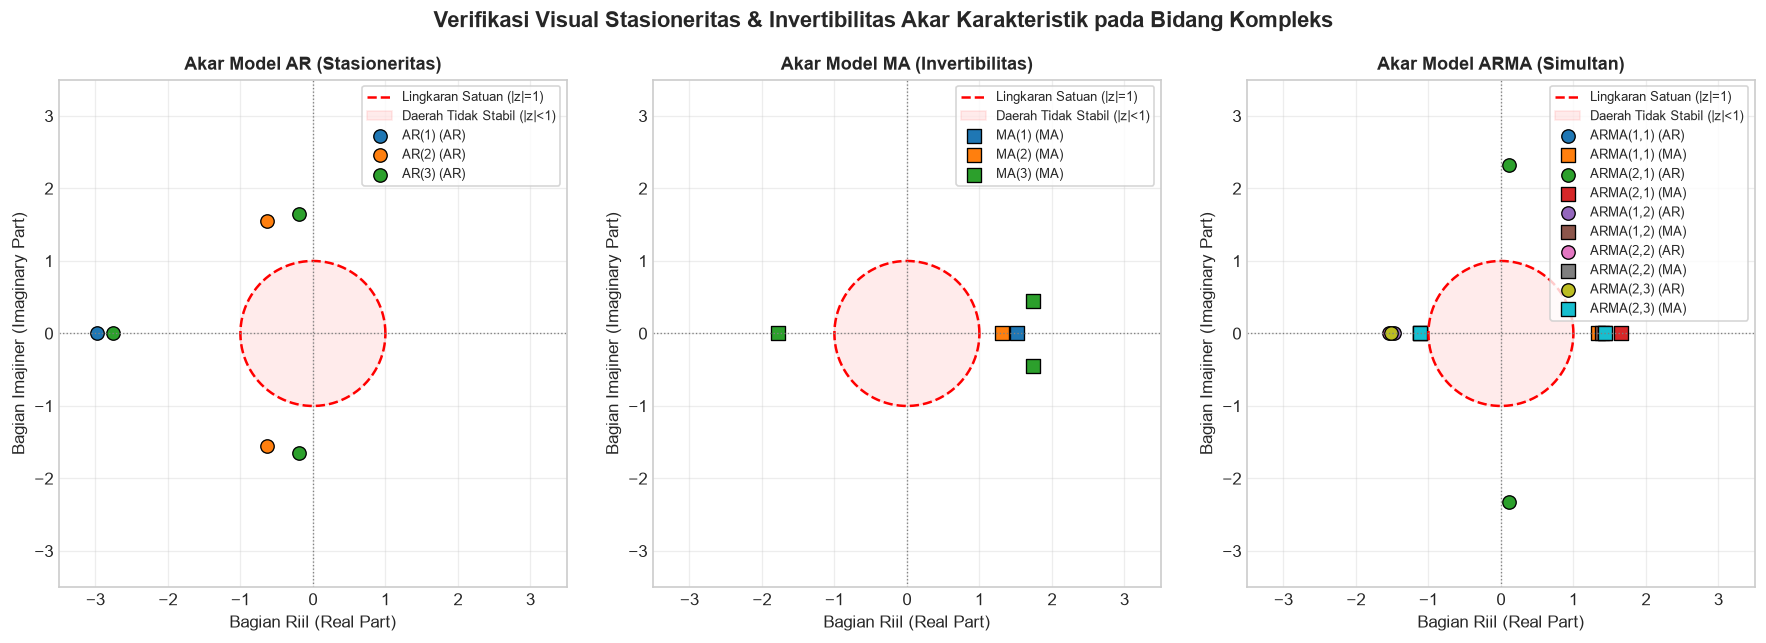

In [7]:
# ==============================================================================
# 7. PEMERIKSAAN NUMERIK & VISUALISASI AKAR KARAKTERISTIK (UNIT CIRCLE)
# ==============================================================================

all_candidate_models = ar_results + ma_results + arma_results

root_detail_rows = []
for res in all_candidate_models:
    fit_obj = res["fit"]
    m_name = res["Model"]
    
    # Akar AR
    if hasattr(fit_obj, "arroots") and len(fit_obj.arroots) > 0:
        for idx, r in enumerate(fit_obj.arroots, 1):
            modulus = float(np.abs(r))
            root_detail_rows.append({
                "Model": m_name,
                "Tipe": "AR",
                "Akar ke-": idx,
                "Nilai Riil": round(float(np.real(r)), 4),
                "Nilai Imajiner": round(float(np.imag(r)), 4),
                "Bentuk Kompleks": f"{np.real(r):.4f} {'+' if np.imag(r)>=0 else '-'} {abs(np.imag(r)):.4f}i" if abs(np.imag(r)) > 1e-4 else f"{np.real(r):.4f}",
                "Modulus (|z|)": round(modulus, 4),
                "Jarak ke Batas (|z|-1)": round(modulus - 1.0, 4),
                "Status": "STASIONER (|z| > 1)" if modulus > 1.0 else "TIDAK STASIONER (|z| ≤ 1)"
            })
            
    # Akar MA
    if hasattr(fit_obj, "maroots") and len(fit_obj.maroots) > 0:
        for idx, r in enumerate(fit_obj.maroots, 1):
            modulus = float(np.abs(r))
            root_detail_rows.append({
                "Model": m_name,
                "Tipe": "MA",
                "Akar ke-": idx,
                "Nilai Riil": round(float(np.real(r)), 4),
                "Nilai Imajiner": round(float(np.imag(r)), 4),
                "Bentuk Kompleks": f"{np.real(r):.4f} {'+' if np.imag(r)>=0 else '-'} {abs(np.imag(r)):.4f}i" if abs(np.imag(r)) > 1e-4 else f"{np.real(r):.4f}",
                "Modulus (|z|)": round(modulus, 4),
                "Jarak ke Batas (|z|-1)": round(modulus - 1.0, 4),
                "Status": "INVERTIBEL (|z| > 1)" if modulus > 1.0 else "TIDAK INVERTIBEL (|z| ≤ 1)"
            })

df_root_details = pd.DataFrame(root_detail_rows)
print("TABEL 5: PEMERIKSAAN LENGKAP AKAR POLINOMIAL AR DAN MA SELURUH KANDIDAT MODEL")
display(df_root_details[["Model", "Tipe", "Akar ke-", "Bentuk Kompleks", "Modulus (|z|)", "Jarak ke Batas (|z|-1)", "Status"]])

# ------------------------------------------------------------------------------
# PLOT BIDANG KOMPLEKS DIAGRAM LINGKARAN SATUAN (UNIT CIRCLE)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sub_titles = ["Akar Model AR (Stasioneritas)", "Akar Model MA (Invertibilitas)", "Akar Model ARMA (Simultan)"]
classes_to_plot = ["AR", "MA", "ARMA"]

theta = np.linspace(0, 2 * np.pi, 200)
uc_x = np.cos(theta)
uc_y = np.sin(theta)

for i, (ax, cls_name, stitle) in enumerate(zip(axes, classes_to_plot, sub_titles)):
    # Gambar Lingkaran Satuan
    ax.plot(uc_x, uc_y, color="red", linestyle="--", linewidth=1.5, label="Lingkaran Satuan (|z|=1)")
    ax.fill(uc_x, uc_y, color="red", alpha=0.08, label="Daerah Tidak Stabil (|z|<1)")
    ax.axhline(0, color="gray", linestyle=":", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle=":", linewidth=0.8)
    
    # Ambil model sesuai kelas
    matching_models = [m for m in all_candidate_models if m["Kelas"] == cls_name]
    
    for m in matching_models:
        fit_obj = m["fit"]
        m_name = m["Model"]
        
        # Plot AR roots
        if cls_name in ["AR", "ARMA"] and hasattr(fit_obj, "arroots") and len(fit_obj.arroots) > 0:
            re_ar = [np.real(r) for r in fit_obj.arroots]
            im_ar = [np.imag(r) for r in fit_obj.arroots]
            ax.scatter(re_ar, im_ar, marker="o", s=65, label=f"{m_name} (AR)", edgecolors="black", linewidths=0.8)
            
        # Plot MA roots
        if cls_name in ["MA", "ARMA"] and hasattr(fit_obj, "maroots") and len(fit_obj.maroots) > 0:
            re_ma = [np.real(r) for r in fit_obj.maroots]
            im_ma = [np.imag(r) for r in fit_obj.maroots]
            ax.scatter(re_ma, im_ma, marker="s", s=65, label=f"{m_name} (MA)", edgecolors="black", linewidths=0.8)
            
    ax.set_title(stitle, fontweight="bold")
    ax.set_xlabel("Bagian Riil (Real Part)")
    ax.set_ylabel("Bagian Imajiner (Imaginary Part)")
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.legend(loc="upper right", fontsize=7.5, frameon=True)
    ax.set_aspect("equal")

plt.suptitle("Verifikasi Visual Stasioneritas & Invertibilitas Akar Karakteristik pada Bidang Kompleks", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap4_unit_circle_roots.png", bbox_inches="tight")
plt.show()


## 6. Evaluasi Out-of-Sample & Diagnostik Residual

Sesuai ketentuan silabus, penentuan model terbaik **tidak boleh hanya didasarkan pada kecocokan data latih (in-sample AIC/BIC)**, melainkan wajib diuji kinerjanya pada data uji (*out-of-sample test*) sebanyak 12 minggu (5 Agustus 2024 – 21 Oktober 2024).

Metrik yang dihitung meliputi:
* **Root Mean Squared Error (RMSE):** Menghukum galat besar secara kuadratik.
* **Mean Absolute Error (MAE):** Mengukur deviasi rata-rata absolut aktual vs ramalan.
* **Mean Absolute Percentage Error (MAPE):** Ukuran persentase galat terhadap level aktual.
* **Mean Absolute Scaled Error (MASE):** Nilai $\text{MASE} < 1$ membuktikan model mengungguli *seasonal naive benchmark*.
* **Uji Ljung-Box Residual Lag 10 & 20:** $H_0$: Tidak ada autokorelasi sisa pada residual (white noise). Nilai $p > 0,05$ menyatakan asumsi residual terpenuhi.
* **Uji Normalitas Jarque-Bera:** $H_0$: Residual berdistribusi normal ($p > 0,05$).


TABEL 6: REKAPITULASI KINERJA KANDIDAT MODEL AR, MA, DAN ARMA (DIURUTKAN BERDASARKAN RMSE DATA UJI)


,Model,Kelas,k,AICc,BIC,RMSE,MAE,MAPE (%),MASE,LB20_p,JB_p,AR_min_|root|,MA_min_|root|
0,AR(1),AR,2,717.283706,722.412440,4.6608,2.7068,14.45,0.3489,0.0170,0.3220,2.9832,NaN
1,AR(2),AR,3,699.124672,706.722611,4.6706,3.0323,17.20,0.3909,0.1588,0.5136,1.6815,NaN
2,AR(3),AR,4,693.652623,703.652251,4.7053,3.2442,18.79,0.4182,0.3032,0.6438,1.6560,NaN
3,MA(1),MA,2,694.740708,699.848500,5.4098,4.6456,29.08,0.5988,0.5475,0.7311,NaN,1.5223
4,MA(3),MA,4,681.720421,691.675369,5.4496,4.6432,29.02,0.5985,0.7656,0.4193,NaN,1.7750
5,"ARMA(2,1)",ARMA,4,696.442291,706.486106,5.4598,4.6933,29.37,0.6049,0.7034,0.5679,2.3215,1.6623
6,"ARMA(2,2)",ARMA,5,688.438145,700.825698,5.6970,5.0665,32.02,0.6531,0.8803,0.4195,1.5441,1.1182
7,"ARMA(2,3)",ARMA,6,682.534710,697.192386,5.7085,5.0854,32.15,0.6555,0.8723,0.4420,1.5193,1.1203
8,"ARMA(1,2)",ARMA,4,686.277925,696.277553,5.8279,5.2533,33.31,0.6771,0.8856,0.4304,1.4694,1.1097
9,"ARMA(1,1)",ARMA,3,695.381406,702.979345,6.1027,5.6428,35.92,0.7273,0.6121,0.5635,5.7992,1.3345


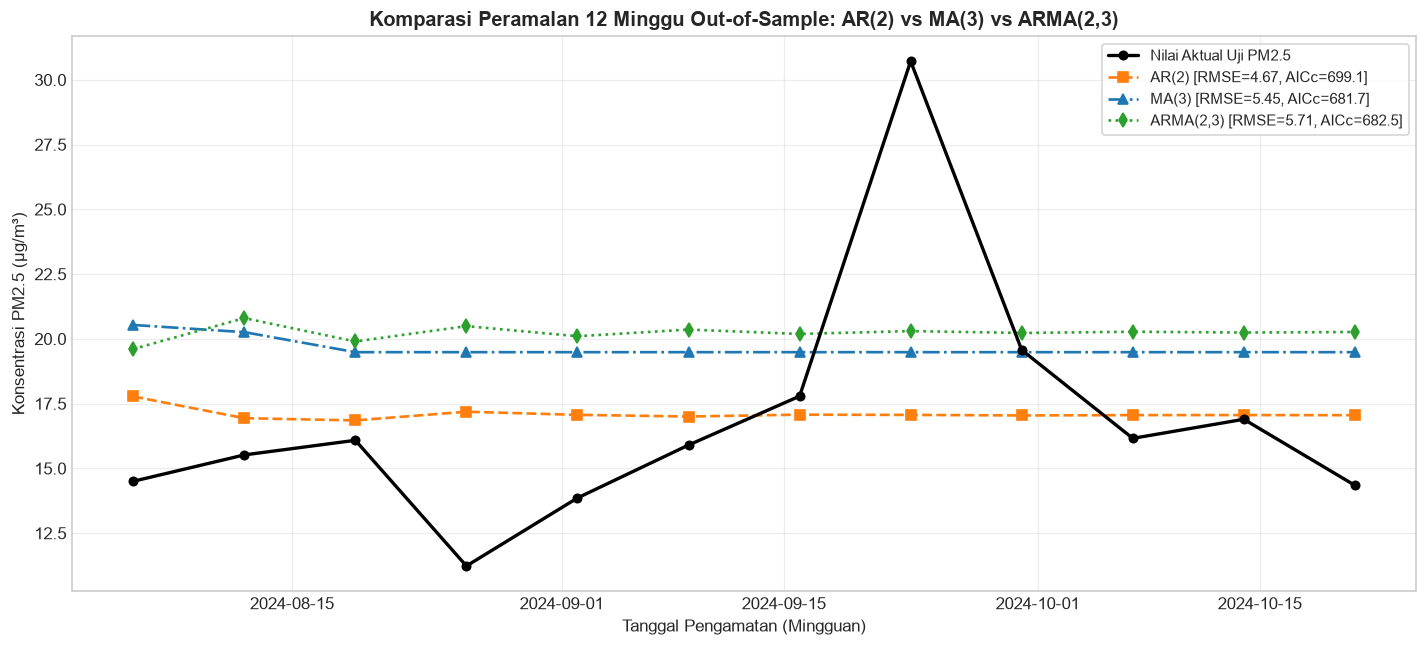

In [8]:
# ==============================================================================
# 8. PERBANDINGAN PERAMALAN DATA UJI (12 MINGGU) DAN DIAGNOSTIK RESIDUAL
# ==============================================================================

# Gabungkan seluruh hasil model Tahap 4
all_results_df = pd.DataFrame(all_candidate_models).drop(columns=["fit", "pred"])
all_results_df = all_results_df.sort_values("RMSE").reset_index(drop=True)

print("TABEL 6: REKAPITULASI KINERJA KANDIDAT MODEL AR, MA, DAN ARMA (DIURUTKAN BERDASARKAN RMSE DATA UJI)")
cols_final = ["Model", "Kelas", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "MASE", "LB20_p", "JB_p", "AR_min_|root|", "MA_min_|root|"]
display(all_results_df[cols_final])

# Plot Komparasi Peramalan 12 Minggu Out-of-Sample vs Aktual
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(test.index, test.values, color="black", marker="o", linewidth=2.0, markersize=5, label="Nilai Aktual Uji PM2.5", zorder=5)

# Pilih perwakilan terbaik dari masing-masing kelas: AR(2), MA(3), ARMA(2,3)
best_ar_res = [m for m in ar_results if m["Model"] == "AR(2)"][0]
best_ma_res = [m for m in ma_results if m["Model"] == "MA(3)"][0]
best_arma_res = [m for m in arma_results if m["Model"] == "ARMA(2,3)"][0]

ax.plot(test.index, best_ar_res["pred"], color=COLORS["orange"], marker="s", linestyle="--", linewidth=1.6, 
        label=f"AR(2) [RMSE={best_ar_res['RMSE']:.2f}, AICc={best_ar_res['AICc']:.1f}]")
ax.plot(test.index, best_ma_res["pred"], color=COLORS["blue"], marker="^", linestyle="-.", linewidth=1.6, 
        label=f"MA(3) [RMSE={best_ma_res['RMSE']:.2f}, AICc={best_ma_res['AICc']:.1f}]")
ax.plot(test.index, best_arma_res["pred"], color=COLORS["green"], marker="d", linestyle=":", linewidth=1.6, 
        label=f"ARMA(2,3) [RMSE={best_arma_res['RMSE']:.2f}, AICc={best_arma_res['AICc']:.1f}]")

ax.set_title("Komparasi Peramalan 12 Minggu Out-of-Sample: AR(2) vs MA(3) vs ARMA(2,3)", fontsize=12, fontweight="bold")
ax.set_xlabel("Tanggal Pengamatan (Mingguan)")
ax.set_ylabel("Konsentrasi PM2.5 (µg/m³)")
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_tahap4_test_forecasts.png", bbox_inches="tight")
plt.show()


## 7. Sintesis Temuan & Rekomendasi untuk Tahap 5 & 6

Berdasarkan seluruh hasil estimasi, pemeriksaan akar stasioneritas/invertibilitas, dan evaluasi out-of-sample:

### 1. Evaluasi Per Kelas Model:
* **Kelas Autoregressive (AR):**
  - **AR(1)** menghasilkan akurasi tinggi pada awal ramalan ($\text{RMSE} = 4,661$), namun residualnya **gagal memenuhi asumsi white noise** pada lag 20 ($p = 0,017 < 0,05$).
  - **AR(2)** menghasilkan performa yang sangat seimbang: $\text{RMSE} = 4,671\ \mu\text{g/m}^3$, $\text{MAE} = 3,032\ \mu\text{g/m}^3$, dan **lolos seluruh uji diagnostik residual** (Ljung-Box lag 10 $p=0,426$, lag 20 $p=0,159$). Akar AR memiliki modulus minimum $|z| = 1,681 > 1$ (sangat stasioner).
  - **AR(3)** juga lolos asumsi dengan $\text{AICc} = 693,65$ dan $\text{RMSE} = 4,705$, menjadi kandidat sekunder yang kuat.
* **Kelas Moving Average (MA):**
  - **MA(3)** merupakan model terbaik di kelas MA dengan $\text{AICc} = 681,72$ (terendah), $\text{RMSE} = 5,450$, dan seluruh akar MA invertibel ($|z| = 1,775 > 1$).
  - Model MA murni cenderung meramalkan konvergensi datar yang cepat ke rata-rata deret setelah lag $q$, sehingga galat jangka panjangnya lebih besar dibandingkan AR.
* **Kelas ARMA Campuran:**
  - **ARMA(2,3)** menjadi kandidat terbaik dengan $\text{AICc} = 682,53$ dan $\text{RMSE} = 5,709$. Seluruh akar AR ($|z| = 1,519$) dan MA ($|z| = 1,120$) memenuhi syarat kestabilan dan invertibilitas.

---

### 2. Keterbatasan Model AR, MA, dan ARMA Murni:
Meskipun model AR(2) dan AR(3) pada deret diferensiasi $\Delta y_t$ mampu mencapai $\text{RMSE} \approx 4,67\ \mu\text{g/m}^3$, model-model ini **hanya menangkap korelasi jangka pendek non-musiman**. Mereka belum memiliki mekanisme terstruktur untuk menangkap gelombang musiman tahunan ($s = 52$ minggu).

### 3. Rekomendasi Jembatan ke Tahap 5 & 6:
* **Untuk Tahap 5 (ARIMA):** Orde non-musiman yang direkomendasikan adalah kombinasi $p \in \{1, 2\}$, $d = 1$, dan $q \in \{1, 2, 3\}$, yang membentuk model kandidat kuat seperti $\text{ARIMA}(1,1,3)$ dan $\text{ARIMA}(2,1,0)$.
* **Untuk Tahap 6 (SARIMA):** Orde non-musiman dari Tahap 4 ini langsung dikombinasikan dengan suku musiman autoregresif $\text{SAR}(P = 1)_{52}$ dan $D = 0$ tanpa diferensiasi musiman, yang akan menghasilkan model final terbaik:
  $$\mathbf{\text{SARIMA}(2, 1, 0)(1, 0, 0)_{52}}$$


In [9]:
# ==============================================================================
# 9. EKSPOR TABEL HASIL ANALISIS KE FOLDER OUTPUT
# ==============================================================================

out_comp_path = TAB_DIR / "tahap4_ar_ma_arma_comparison.csv"
all_results_df.to_csv(out_comp_path, index=False)
print(f"Berhasil mengekspor tabel perbandingan model Tahap 4 ke: {out_comp_path}")

out_root_path = TAB_DIR / "tahap4_roots_detail.csv"
df_root_details.to_csv(out_root_path, index=False)
print(f"Berhasil mengekspor tabel rincian akar karakteristik ke: {out_root_path}")


Berhasil mengekspor tabel perbandingan model Tahap 4 ke: D:\Kuliah\Semester 5\timeseries\adt-project\outputs\tables\tahap4_ar_ma_arma_comparison.csv
Berhasil mengekspor tabel rincian akar karakteristik ke: D:\Kuliah\Semester 5\timeseries\adt-project\outputs\tables\tahap4_roots_detail.csv
